<a href="https://colab.research.google.com/github/madhuraspatil/AIML_Theory/blob/main/Activity_No_1_Machine_Learning_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

ARTIFICIAL AND MACHINE LEARNING

PROJECT GROUP MEMBERS NAME:

ABHISHEK PATIL(202401040050)

PARTH WANKHADE(202401040052)

MADHURA PATIL(202401040094)


Title
Implementation and Comparative Analysis of Classification Algorithms Using Machine Learning

Aim
To implement and compare different classification algorithms, namely Support Vector Machine (SVM), Decision Tree (CART), K-Nearest Neighbors (KNN), and Naive Bayes, using a Bank Marketing dataset.

Objectives
To understand the concept and working of classification in machine learning.

To implement four different classification algorithms using Python.

To train and test the classification models using a dataset.

To evaluate model performance using Accuracy, Precision, Recall, F1-score and Log Loss.

To generate confusion matrices and performance comparison graphs.

To identify the best-performing classification algorithm based on evaluation metrics.

Outcome
Successfully implemented SVM, Decision Tree, KNN and Naive Bayes classification algorithms.

Trained and tested all four models using the Bank Marketing dataset.

Evaluated the models using different performance metrics.

Visualized and compared the performance of all classification algorithms.

Identified the best-performing model based on its F1-score and Log Loss.

Gained practical knowledge of classification techniques and model evaluation in machine learning.



In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    log_loss,
    confusion_matrix,
    classification_report
)

print("All libraries imported successfully!")

All libraries imported successfully!


Pandas is used for reading and handling datasets.



NumPy is used for numerical operations.



Matplotlib and Seaborn are used for data visualization.



Scikit-learn provides machine learning algorithms.



We import four classification algorithms for our practical.



Evaluation metrics are imported to measure model performance.

In [ ]:
from google.colab import files

uploaded = files.upload()

df = pd.read_csv('03_duplicates_removed.csv')

print("Dataset loaded successfully!")
print(df.head())

Saving 03_duplicates_removed.csv to 03_duplicates_removed.csv
Dataset loaded successfully!
   age        job  marital    education  default housing loan    contact  \
0   56  housemaid  married     basic.4y       no      no   no  telephone   
1   57   services  married  high.school  unknown      no   no  telephone   
2   37   services  married  high.school       no     yes   no  telephone   
3   40     admin.  married     basic.6y       no      no   no  telephone   
4   56   services  married  high.school       no      no  yes  telephone   

  month day_of_week  ...  campaign  pdays  previous     poutcome emp.var.rate  \
0   may         mon  ...         1    999         0  nonexistent          1.1   
1   may         mon  ...         1    999         0  nonexistent          1.1   
2   may         mon  ...         1    999         0  nonexistent          1.1   
3   may         mon  ...         1    999         0  nonexistent          1.1   
4   may         mon  ...         1    999      

The files.upload() function allows us to upload our CSV file.



Pandas reads the CSV file using read_csv().



The dataset is stored in the variable df.



The head() function displays the first five records.



This helps us understand the structure of the dataset.



Our dataset contains customer information and subscription status.

In [ ]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
print(df.describe())



Dataset Shape: (41176, 21)

Column Names:
Index(['age', 'job', 'marital', 'education', 'default', 'housing', 'loan',
       'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays',
       'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx',
       'cons.conf.idx', 'euribor3m', 'nr.employed', 'y'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41176 entries, 0 to 41175
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41176 non-null  int64  
 1   job             41176 non-null  object 
 2   marital         41176 non-null  object 
 3   education       41176 non-null  object 
 4   default         41176 non-null  object 
 5   housing         41176 non-null  object 
 6   loan            41176 non-null  object 
 7   contact         41176 non-null  object 
 8   month           41176 non-null  object 
 9   day_of_week     41176 non-null  

shape displays the number of rows and columns.



columns displays all the column names.



info() provides information about data types.



describe() displays statistical information.



isnull().sum() identifies missing values.



duplicated() checks whether duplicate records exist.

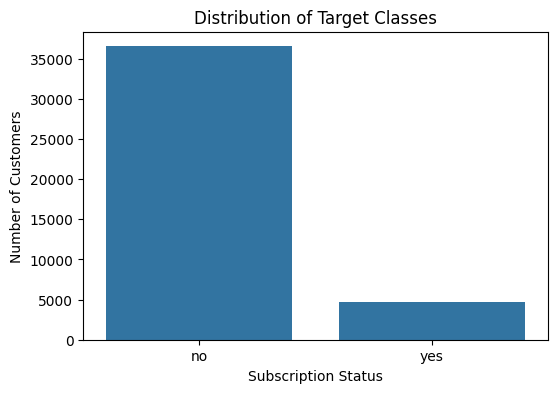

In [ ]:
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x='y')

plt.title("Distribution of Target Classes")
plt.xlabel("Subscription Status")
plt.ylabel("Number of Customers")

plt.show()

Data visualization helps us understand the dataset graphically.



We use a count plot to display the target variable.



The target variable is y.



It contains two classes: Yes and No.



The graph shows how many customers subscribed.



This helps identify class imbalance in the dataset.

In [ ]:
# Separate features and target variable

X = df.drop('y', axis=1)

y = df['y'].map({
    'no': 0,
    'yes': 1
})

print("Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Features:
   age        job  marital    education  default housing loan    contact  \
0   56  housemaid  married     basic.4y       no      no   no  telephone   
1   57   services  married  high.school  unknown      no   no  telephone   
2   37   services  married  high.school       no     yes   no  telephone   
3   40     admin.  married     basic.6y       no      no   no  telephone   
4   56   services  married  high.school       no      no  yes  telephone   

  month day_of_week  duration  campaign  pdays  previous     poutcome  \
0   may         mon       261         1    999         0  nonexistent   
1   may         mon       149         1    999         0  nonexistent   
2   may         mon       226         1    999         0  nonexistent   
3   may         mon       151         1    999         0  nonexistent   
4   may         mon       307         1    999         0  nonexistent   

   emp.var.rate  cons.price.idx  cons.conf.idx  euribor3m  nr.employed  
0           1.1      

Data preprocessing prepares the dataset for machine learning.



X contains all input features.



The y column is separated as the target variable.



The target contains Yes and No values.



Label encoding converts No into 0 and Yes into 1.



This allows algorithms to work with numerical target values.

In [ ]:
numeric_features = X.select_dtypes(
    include=['int64', 'float64']
).columns

categorical_features = X.select_dtypes(
    include=['object']
).columns

print("Numerical Features:")
print(list(numeric_features))

print("\nCategorical Features:")
print(list(categorical_features))

Numerical Features:
['age', 'duration', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

Categorical Features:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']


Numerical features contain numerical values.



Categorical features contain text-based categories.



select_dtypes() identifies the data types automatically.



Numerical features need scaling for algorithms such as KNN and SVM.



Categorical features need encoding.



This separation helps us apply suitable preprocessing techniques.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

print("\nTraining Split:", len(X_train))
print("Testing Split:", len(X_test))

Training Data: (32940, 20)
Testing Data: (8236, 20)

Training Split: 32940
Testing Split: 8236


We divide the dataset into training and testing portions.



80% of the data is used for training.



20% of the data is used for testing.



random_state=42 ensures reproducible results.



stratify=y maintains the proportion of Yes and No classes.



Training data teaches the model, while testing data evaluates its performance.

In [ ]:
# Select only the numeric features to avoid any preprocessing
X_train_numeric = X_train[numeric_features]
X_test_numeric = X_test[numeric_features]

svm_model = Pipeline([
    ('classifier', CalibratedClassifierCV(
        estimator=LinearSVC(
            class_weight='balanced',
            max_iter=5000,
            random_state=42
        ),
        cv=3
    ))
])

# Train using only numerical data without preprocessing
svm_model.fit(X_train_numeric, y_train)

svm_predictions = svm_model.predict(X_test_numeric)

print("SVM Model Trained Successfully on numeric columns!")

SVM Model Trained Successfully on numeric columns!


SVM is a supervised machine learning classification algorithm.



It finds an optimal decision boundary to separate different classes.



We use LinearSVC to efficiently handle our large dataset.



Class balancing helps address differences in the number of Yes and No records.



Calibration allows the model to generate probability predictions.



The model is trained using fit() and predicts using predict().

In [ ]:
dt_model = Pipeline([
    ('classifier', DecisionTreeClassifier(
        criterion='gini',
        max_depth=10,
        class_weight='balanced',
        random_state=42
    ))
])

dt_model.fit(X_train_numeric, y_train)

dt_predictions = dt_model.predict(X_test_numeric)

print("Decision Tree Model Trained Successfully!")

Decision Tree Model Trained Successfully!


Decision Tree is a supervised classification algorithm.



It uses a tree-like structure to make decisions.



CART stands for Classification and Regression Trees.



The Gini index is used to measure impurity.



The maximum depth is limited to 10 to control model complexity.



The model predicts the class based on learned decision rules.

In [ ]:
knn_model = Pipeline([
    ('classifier', KNeighborsClassifier(
        n_neighbors=5,
        metric='minkowski',
        p=2
    ))
])

knn_model.fit(X_train_numeric, y_train)

knn_predictions = knn_model.predict(X_test_numeric)

print("KNN Model Trained Successfully!")

KNN Model Trained Successfully!


KNN is a distance-based classification algorithm.



It identifies the nearest data points to a new observation.



We select K = 5 neighbours.



Minkowski distance with p = 2 represents Euclidean distance.



The majority class among the five neighbours determines the prediction.



Feature scaling is important because KNN depends on distance calculations.

In [ ]:
nb_model = Pipeline([
    ('classifier', GaussianNB())
])

nb_model.fit(X_train_numeric, y_train)

nb_predictions = nb_model.predict(X_test_numeric)

print("Naive Bayes Model Trained Successfully!")

Naive Bayes Model Trained Successfully!


Naive Bayes is a probability-based classification algorithm.



It uses Bayes' theorem to calculate class probabilities.



Gaussian Naive Bayes assumes numerical features follow a Gaussian distribution.



It assumes that features are conditionally independent given the class.



The model calculates the probability of each class.



The class with the highest predicted probability is selected.

In [ ]:
models = {
    'SVM': svm_model,
    'Decision Tree': dt_model,
    'KNN': knn_model,
    'Naive Bayes': nb_model
}

results = []

for name, model in models.items():
    predictions = model.predict(X_test_numeric)
    probabilities = model.predict_proba(X_test_numeric)

    accuracy = accuracy_score(y_test, predictions)
    precision = precision_score(y_test, predictions, zero_division=0)
    recall = recall_score(y_test, predictions, zero_division=0)
    f1 = f1_score(y_test, predictions, zero_division=0)
    loss = log_loss(y_test, probabilities)

    results.append({
        'Model': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1,
        'Log Loss': loss
    })

results_df = pd.DataFrame(results)
print(results_df.round(4))

           Model  Accuracy  Precision  Recall  F1 Score  Log Loss
0            SVM    0.9078     0.6528  0.3890    0.4875    0.2205
1  Decision Tree    0.8542     0.4284  0.8804    0.5764    0.6988
2            KNN    0.9038     0.5879  0.4903    0.5347    0.8912
3    Naive Bayes    0.8768     0.4634  0.5927    0.5201    0.9899


This block evaluates the performance of all four models.



Accuracy measures the overall correct predictions.



Precision measures how many positive predictions are correct.



Recall measures how many actual positive cases are identified.



F1-score calculates the balance between precision and recall.



Log Loss measures the quality of predicted probabilities; lower values are better.

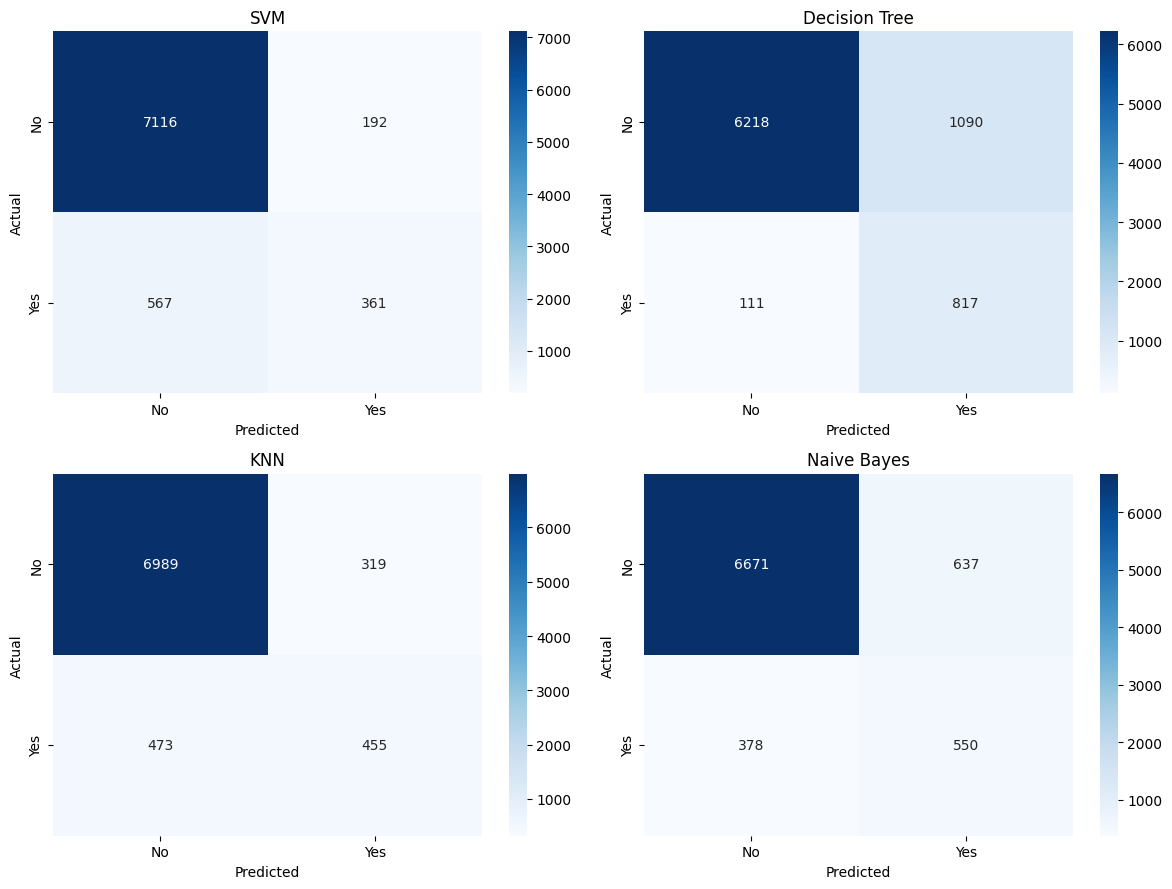

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

for ax, (name, model) in zip(axes.flatten(), models.items()):
    predictions = model.predict(X_test_numeric)
    cm = confusion_matrix(y_test, predictions)

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        xticklabels=['No', 'Yes'],
        yticklabels=['No', 'Yes'],
        ax=ax
    )
    ax.set_title(name)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

A confusion matrix evaluates classification predictions.



It compares actual values with predicted values.



True Positive represents correctly predicted Yes cases.



True Negative represents correctly predicted No cases.



False Positive and False Negative represent incorrect predictions.



We generate separate confusion matrices for all four algorithms.

In [ ]:
for name, model in models.items():
    print("\nClassification Report:", name)
    predictions = model.predict(X_test_numeric)
    print(
        classification_report(
            y_test,
            predictions,
            target_names=['No', 'Yes'],
            zero_division=0
        )
    )


Classification Report: SVM
              precision    recall  f1-score   support

          No       0.93      0.97      0.95      7308
         Yes       0.65      0.39      0.49       928

    accuracy                           0.91      8236
   macro avg       0.79      0.68      0.72      8236
weighted avg       0.90      0.91      0.90      8236


Classification Report: Decision Tree
              precision    recall  f1-score   support

          No       0.98      0.85      0.91      7308
         Yes       0.43      0.88      0.58       928

    accuracy                           0.85      8236
   macro avg       0.71      0.87      0.74      8236
weighted avg       0.92      0.85      0.87      8236


Classification Report: KNN
              precision    recall  f1-score   support

          No       0.94      0.96      0.95      7308
         Yes       0.59      0.49      0.53       928

    accuracy                           0.90      8236
   macro avg       0.76      0.72 

Classification Report provides a detailed evaluation of each model.



It displays precision for both classes.



It displays recall for both classes.



It displays F1-score for both classes.



Support indicates the number of actual samples in each class.



Macro and weighted averages summarize the performance across classes.

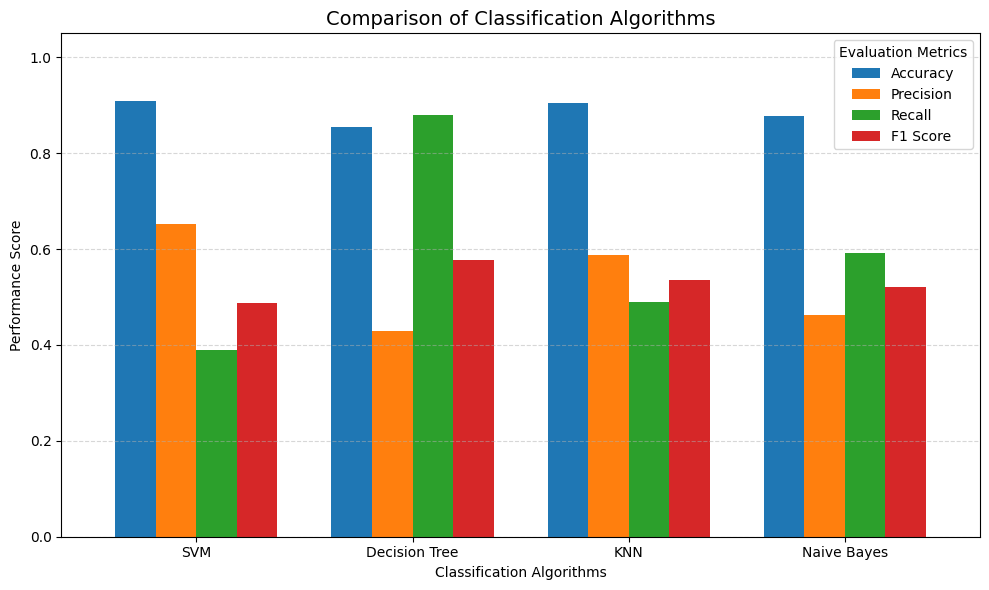

In [ ]:
metrics = ['Accuracy', 'Precision', 'Recall', 'F1 Score']

# Create comparison graph
ax = results_df.set_index('Model')[metrics].plot(
    kind='bar',
    figsize=(10, 6),
    width=0.75
)

plt.title('Comparison of Classification Algorithms', fontsize=14)
plt.xlabel('Classification Algorithms')
plt.ylabel('Performance Score')
plt.ylim(0, 1.05)

plt.xticks(rotation=0)
plt.legend(title='Evaluation Metrics')
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

Comparative analysis helps us compare all four classification algorithms.



We use a bar graph to visualize their performance.



Accuracy, precision, recall and F1-score are compared.



Higher values generally indicate better performance.



The graph helps identify which algorithm performs better.



This comparison helps us understand the strengths of each model.

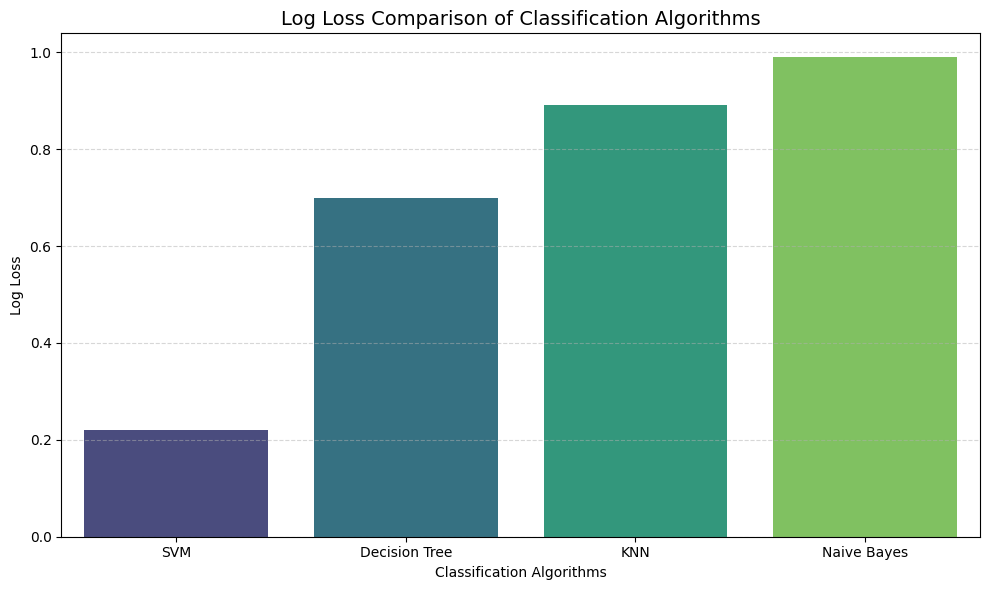

In [ ]:
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=results_df,
    x='Model',
    y='Log Loss',
    hue='Model',
    palette='viridis',
    legend=False
)

plt.title('Log Loss Comparison of Classification Algorithms', fontsize=14)
plt.xlabel('Classification Algorithms')
plt.ylabel('Log Loss')

plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

Log Loss evaluates the probability predictions of classification models.



It measures how close predicted probabilities are to actual outcomes.



Lower Log Loss indicates better probability predictions.



Higher Log Loss indicates poorer probability predictions.



We compare the Log Loss values of all four algorithms.



This helps evaluate the confidence and quality of predictions.

In [ ]:
best_model = results_df.loc[
    results_df['F1 Score'].idxmax()
]

print("Best Performing Model:")
print(best_model.to_string())

print("\nBest Algorithm:", best_model['Model'])
print("Accuracy:", best_model['Accuracy'])
print("Precision:", best_model['Precision'])
print("Recall:", best_model['Recall'])
print("F1 Score:", best_model['F1 Score'])
print("Log Loss:", best_model['Log Loss'])

Best Performing Model:
Model        Decision Tree
Accuracy          0.854177
Precision         0.428422
Recall            0.880388
F1 Score          0.576367
Log Loss          0.698826

Best Algorithm: Decision Tree
Accuracy: 0.8541767848470131
Precision: 0.42842160461457784
Recall: 0.8803879310344828
F1 Score: 0.5763668430335097
Log Loss: 0.6988256501513579


This block identifies the best-performing classification algorithm.



We use F1-score as the selection criterion.



idxmax() finds the row with the highest F1-score.



The selected model is displayed with its evaluation metrics.



A higher F1-score indicates a better balance between precision and recall.



The result helps us select a suitable classification model for this dataset.

In [ ]:
print("========== FINAL CONCLUSION ==========")

print("Four classification algorithms were implemented:")
print("1. Support Vector Machine (SVM)")
print("2. Decision Tree (CART)")
print("3. K-Nearest Neighbors (KNN)")
print("4. Naive Bayes")

print("\nPerformance Comparison:")
print(results_df.round(4).to_string(index=False))

print("\nBest Performing Algorithm:")
print(best_model['Model'])

print("\nClassification practical completed successfully!")

========== FINAL CONCLUSION ==========
Four classification algorithms were implemented:
1. Support Vector Machine (SVM)
2. Decision Tree (CART)
3. K-Nearest Neighbors (KNN)
4. Naive Bayes

Performance Comparison:
        Model  Accuracy  Precision  Recall  F1 Score  Log Loss
          SVM    0.9078     0.6528  0.3890    0.4875    0.2205
Decision Tree    0.8542     0.4284  0.8804    0.5764    0.6988
          KNN    0.9038     0.5879  0.4903    0.5347    0.8912
  Naive Bayes    0.8768     0.4634  0.5927    0.5201    0.9899

Best Performing Algorithm:
Decision Tree

Classification practical completed successfully!


1. In this practical, we implemented four classification algorithms.
2. We trained and tested each model using the Bank Marketing dataset.
3. Their performance was evaluated using different classification metrics.
4. We compared accuracy, precision, recall, F1-score and Log Loss.
5. The best-performing algorithm was identified using F1-score.
6. This practical demonstrates how different algorithms solve classification problems.

In [ ]:
comparison = results_df.sort_values(
    by='F1 Score',
    ascending=False
)

print("CLASSIFICATION ALGORITHM COMPARISON")
display(comparison.round(4))

CLASSIFICATION ALGORITHM COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,Log Loss
1,Decision Tree,0.8542,0.4284,0.8804,0.5764,0.6988
2,KNN,0.9038,0.5879,0.4903,0.5347,0.8912
3,Naive Bayes,0.8768,0.4634,0.5927,0.5201,0.9899
0,SVM,0.9078,0.6528,0.3890,0.4875,0.2205


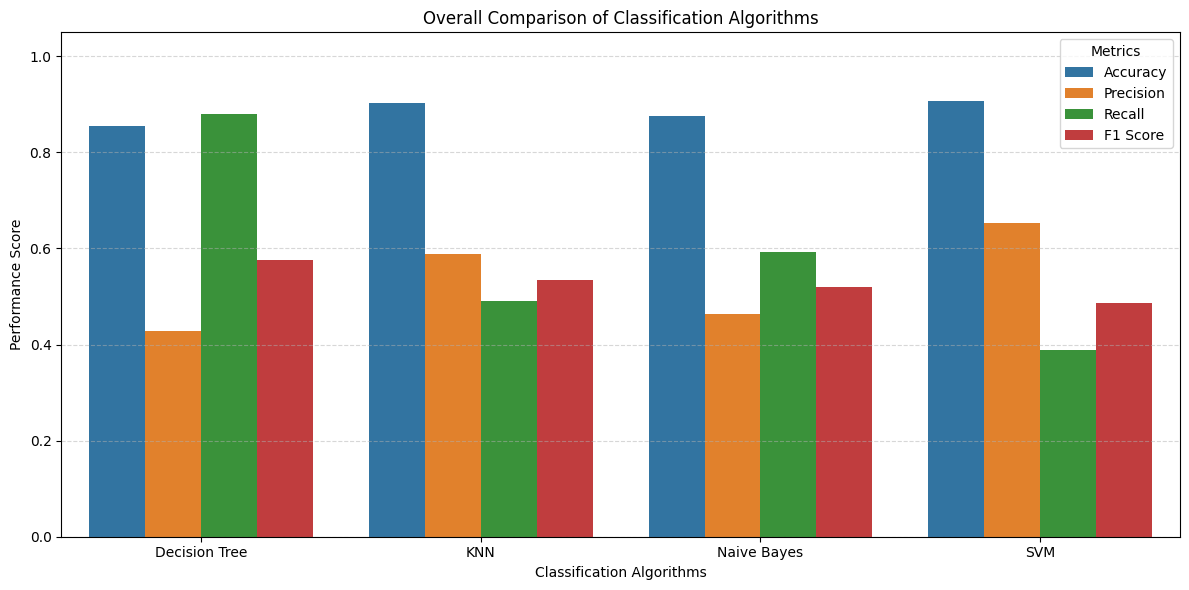

In [ ]:
metrics = [
    'Accuracy',
    'Precision',
    'Recall',
    'F1 Score'
]

plt.figure(figsize=(12, 6))

comparison_melted = comparison.melt(
    id_vars='Model',
    value_vars=metrics,
    var_name='Evaluation Metric',
    value_name='Score'
)

sns.barplot(
    data=comparison_melted,
    x='Model',
    y='Score',
    hue='Evaluation Metric'
)

plt.title('Overall Comparison of Classification Algorithms')
plt.xlabel('Classification Algorithms')
plt.ylabel('Performance Score')
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(title='Metrics')
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

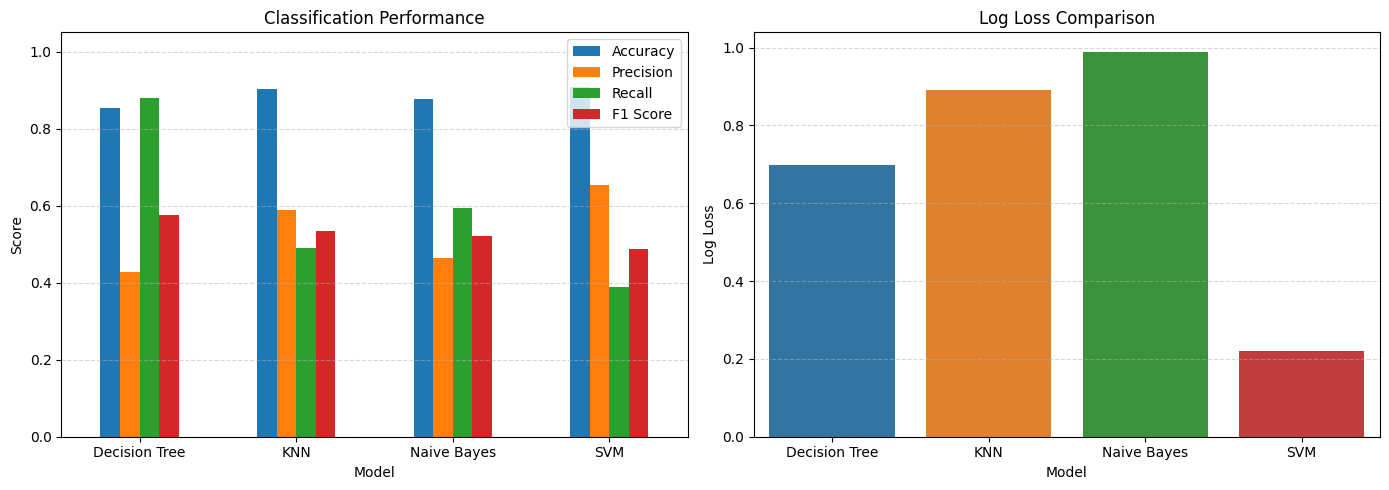

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Performance metrics
comparison.set_index('Model')[
    ['Accuracy', 'Precision', 'Recall', 'F1 Score']
].plot(kind='bar', ax=axes[0])

axes[0].set_title('Classification Performance')
axes[0].set_ylabel('Score')
axes[0].set_ylim(0, 1.05)
axes[0].tick_params(axis='x', rotation=0)
axes[0].grid(axis='y', linestyle='--', alpha=0.5)

# Log Loss
sns.barplot(
    data=comparison,
    x='Model',
    y='Log Loss',
    hue='Model',
    legend=False,
    ax=axes[1]
)

axes[1].set_title('Log Loss Comparison')
axes[1].set_ylabel('Log Loss')
axes[1].tick_params(axis='x', rotation=0)
axes[1].grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [ ]:
best_model = comparison.loc[
    comparison['F1 Score'].idxmax()
]

print("BEST CLASSIFICATION ALGORITHM")
print("--------------------------------")
print("Algorithm:", best_model['Model'])
print("Accuracy:", round(best_model['Accuracy'], 4))
print("Precision:", round(best_model['Precision'], 4))
print("Recall:", round(best_model['Recall'], 4))
print("F1 Score:", round(best_model['F1 Score'], 4))
print("Log Loss:", round(best_model['Log Loss'], 4))

BEST CLASSIFICATION ALGORITHM
--------------------------------
Algorithm: Decision Tree
Accuracy: 0.8542
Precision: 0.4284
Recall: 0.8804
F1 Score: 0.5764
Log Loss: 0.6988
